In [40]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [41]:
from sklearn.preprocessing import LabelEncoder

**EDA**

In [42]:
df=pd.read_csv("Ecommerce.csv")
da=df.copy()

In [43]:
da.head(3)

,CID,TID,Gender,Age Group,Purchase Date,Product Category,Discount Availed,Discount Name,Discount Amount (INR),Gross Amount,Net Amount,Purchase Method,Location
0,943146,5876328741,Female,25-45,30-08-2023 20:27,Electronics,Yes,FESTIVE50,64.30,725.304000,661.004000,Credit Card,Ahmedabad
1,180079,1018503182,Male,25-45,23-02-2024 09:33,Electronics,Yes,SEASONALOFFER21,175.19,4638.991875,4463.801875,Credit Card,Bangalore
2,337580,3814082218,Other,60 and above,06-03-2022 09:09,Clothing,Yes,SEASONALOFFER21,211.54,1986.372575,1774.832575,Credit Card,Delhi


In [44]:
da.isna().sum()/len(da)

,0
CID,0.000000
TID,0.000000
Gender,0.000000
Age Group,0.000000
Purchase Date,0.000000
Product Category,0.000000
Discount Availed,0.000000
Discount Name,0.501573
Discount Amount (INR),0.000000
Gross Amount,0.000000


In [45]:
da["Discount Name"]=da["Discount Name"].fillna("NEWYEARS")

In [46]:
da.dropna(inplace=True)

In [47]:
da=da.drop(columns={"CID","TID"})

In [48]:
da.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54979 entries, 0 to 54978
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Gender                 54979 non-null  object 
 1   Age Group              54979 non-null  object 
 2   Purchase Date          54979 non-null  object 
 3   Product Category       54979 non-null  object 
 4   Discount Availed       54979 non-null  object 
 5   Discount Name          54979 non-null  object 
 6   Discount Amount (INR)  54979 non-null  float64
 7   Gross Amount           54979 non-null  float64
 8   Net Amount             54979 non-null  float64
 9   Purchase Method        54979 non-null  object 
 10  Location               54979 non-null  object 
dtypes: float64(3), object(8)
memory usage: 4.6+ MB


In [49]:
da["Purchase Date"]=pd.to_datetime(da["Purchase Date"])

/tmp/ipykernel_4531/4140654879.py:1: UserWarning: Parsing dates in %d-%m-%Y %H:%M format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  da["Purchase Date"]=pd.to_datetime(da["Purchase Date"])


In [50]:
cat_col=da.select_dtypes(include=object).columns

In [51]:
num_col=da.select_dtypes(exclude=object).columns

In [52]:
da["Purchase Method"]=da["Purchase Method"].replace({"Paytm UPI":"UPI","PhonePe UPI":"UPI","Google Pay UPI":"UPI"})

In [53]:
da["Age Group"]=da["Age Group"].replace({"25-45":"Young","18-25":"Adult","45-60":"Mid Age","under 18":"Teen","60 and above":"Senior"})

In [54]:
# Dumies
#df=pd.get_dummies(df,drop_first=True)

<Axes: xlabel='Net Amount'>

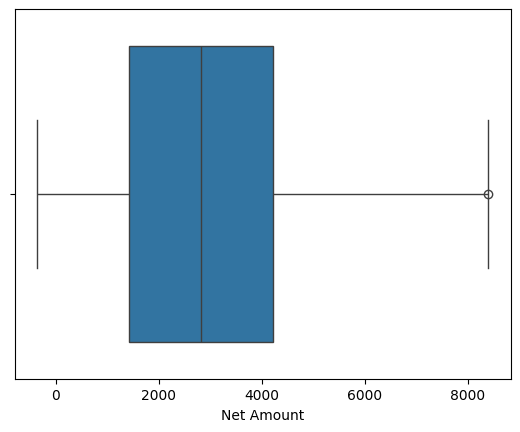

In [55]:
sns.boxplot(x=da["Net Amount"])

<Axes: xlabel='Discount Amount (INR)', ylabel='Count'>

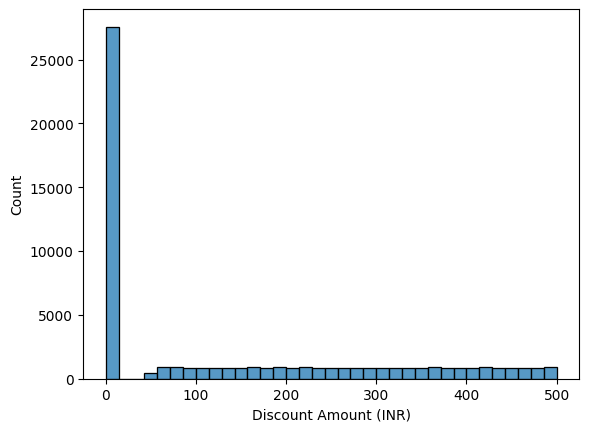

In [56]:
sns.histplot(x=da["Discount Amount (INR)"])

In [57]:
def UserValueCounts(col):
  print(da[col].value_counts())

In [58]:
UserValueCounts("Discount Amount (INR)")

Discount Amount (INR)
0.00      27576
398.40        6
72.13         6
64.64         5
248.36        5
          ...  
362.14        1
254.02        1
208.58        1
172.48        1
415.75        1
Name: count, Length: 20571, dtype: int64


In [59]:
def UserCountplot(col):
  ax=sns.countplot(x=da[col])
  for container in ax.containers:
    ax.bar_label(container)

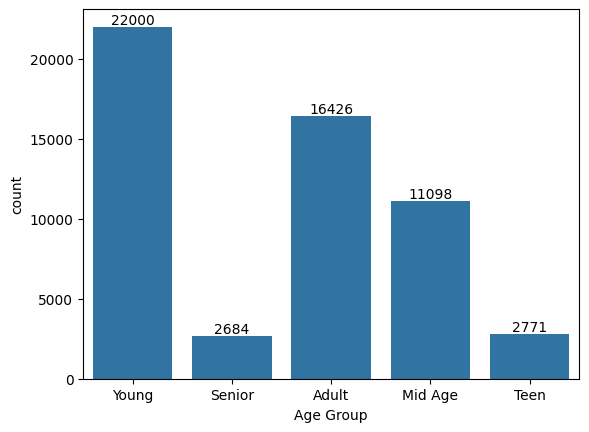

In [60]:
UserCountplot("Age Group")

In [61]:
da["Month"]=da["Purchase Date"].dt.month
da["Year"]=da["Purchase Date"].dt.year

<Axes: xlabel='Net Amount', ylabel='Discount Amount (INR)'>

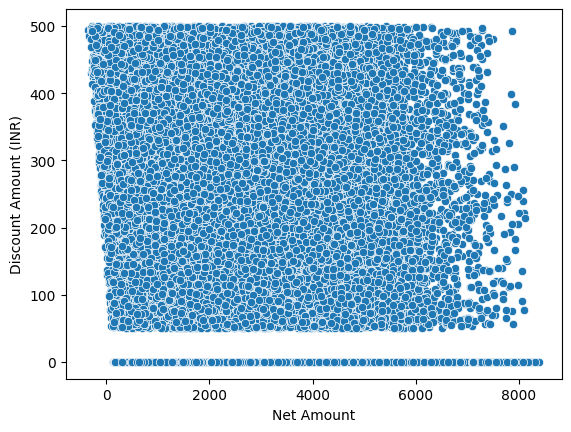

In [66]:
sns.scatterplot(x=da["Net Amount"],y=da["Discount Amount (INR)"])

<Axes: xlabel='Year', ylabel='Net Amount'>

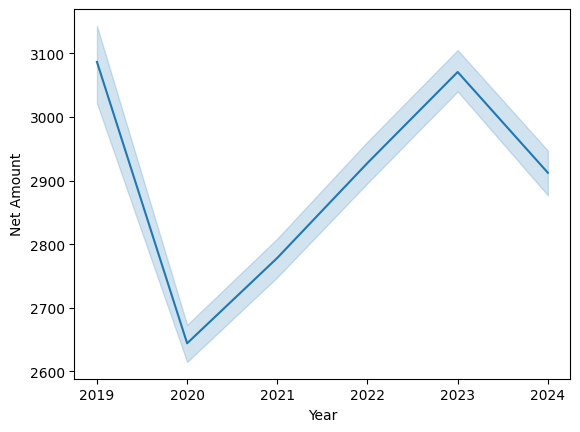

In [64]:
sns.lineplot(x="Year",y="Net Amount",data=da)

<Axes: xlabel='Age Group', ylabel='Gross Amount'>

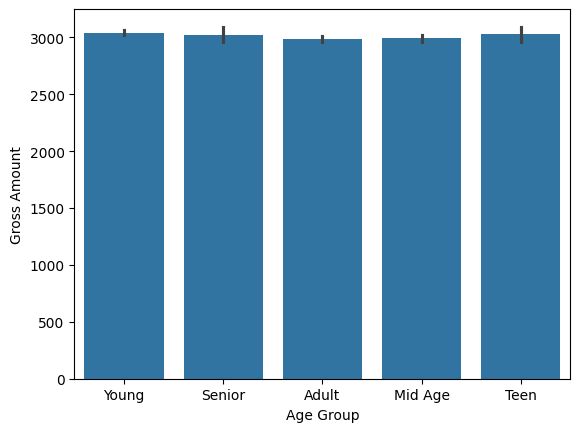

In [68]:
sns.barplot(x=da["Age Group"],y=da["Gross Amount"])

In [74]:
grp1=da.groupby("Age Group").agg(Record=("Age Group",np.size),Avg_Amount=("Net Amount",np.mean),Avg_discount=("Discount Amount (INR)",np.mean))

/tmp/ipykernel_4531/3591483469.py:1: FutureWarning: The provided callable <function mean at 0x7e2e7cfc9a80> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  grp1=da.groupby("Age Group").agg(Record=("Age Group",np.size),Avg_Amount=("Net Amount",np.mean),Avg_discount=("Discount Amount (INR)",np.mean))


In [75]:
grp1

,Record,Avg_Amount,Avg_discount
Age Group,,,
Adult,16426,2848.953116,136.063134
Mid Age,11098,2853.384415,139.050456
Senior,2684,2886.688814,139.323029
Teen,2771,2889.693613,136.816734
Young,22000,2904.539915,136.299883


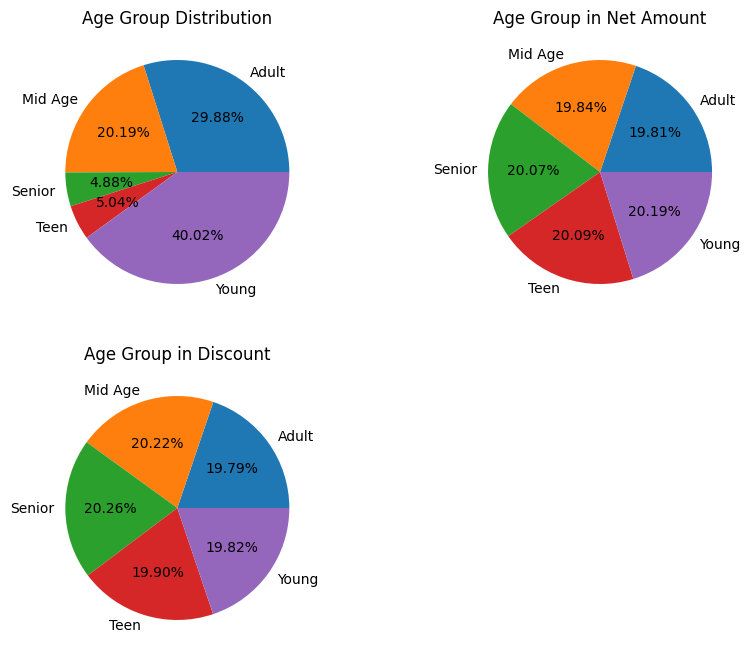

In [84]:
plt.figure(figsize=(10,8))
plt.subplot(2,2,1)
plt.pie(x=grp1.Record.values,labels=grp1.index.values,autopct="%.2f%%")
plt.title("Age Group Distribution")

plt.subplot(2,2,2)
plt.pie(x=grp1.Avg_Amount.values,labels=grp1.index.values,autopct="%.2f%%")
plt.title("Age Group in Net Amount")

plt.subplot(2,2,3)
plt.pie(x=grp1.Avg_discount.values,labels=grp1.index.values,autopct="%.2f%%")
plt.title("Age Group in Discount")

plt.show()

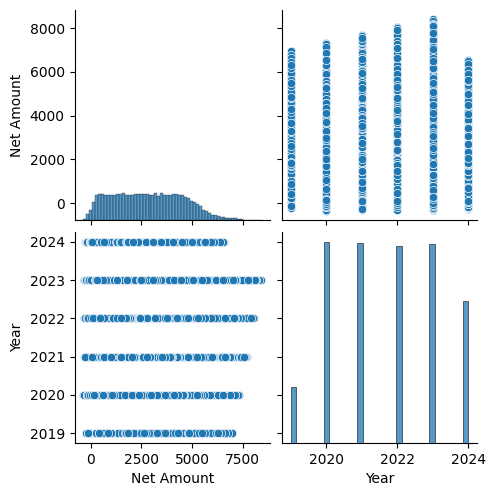

In [71]:
sns.pairplot(da[["Age Group","Net Amount","Year"]])

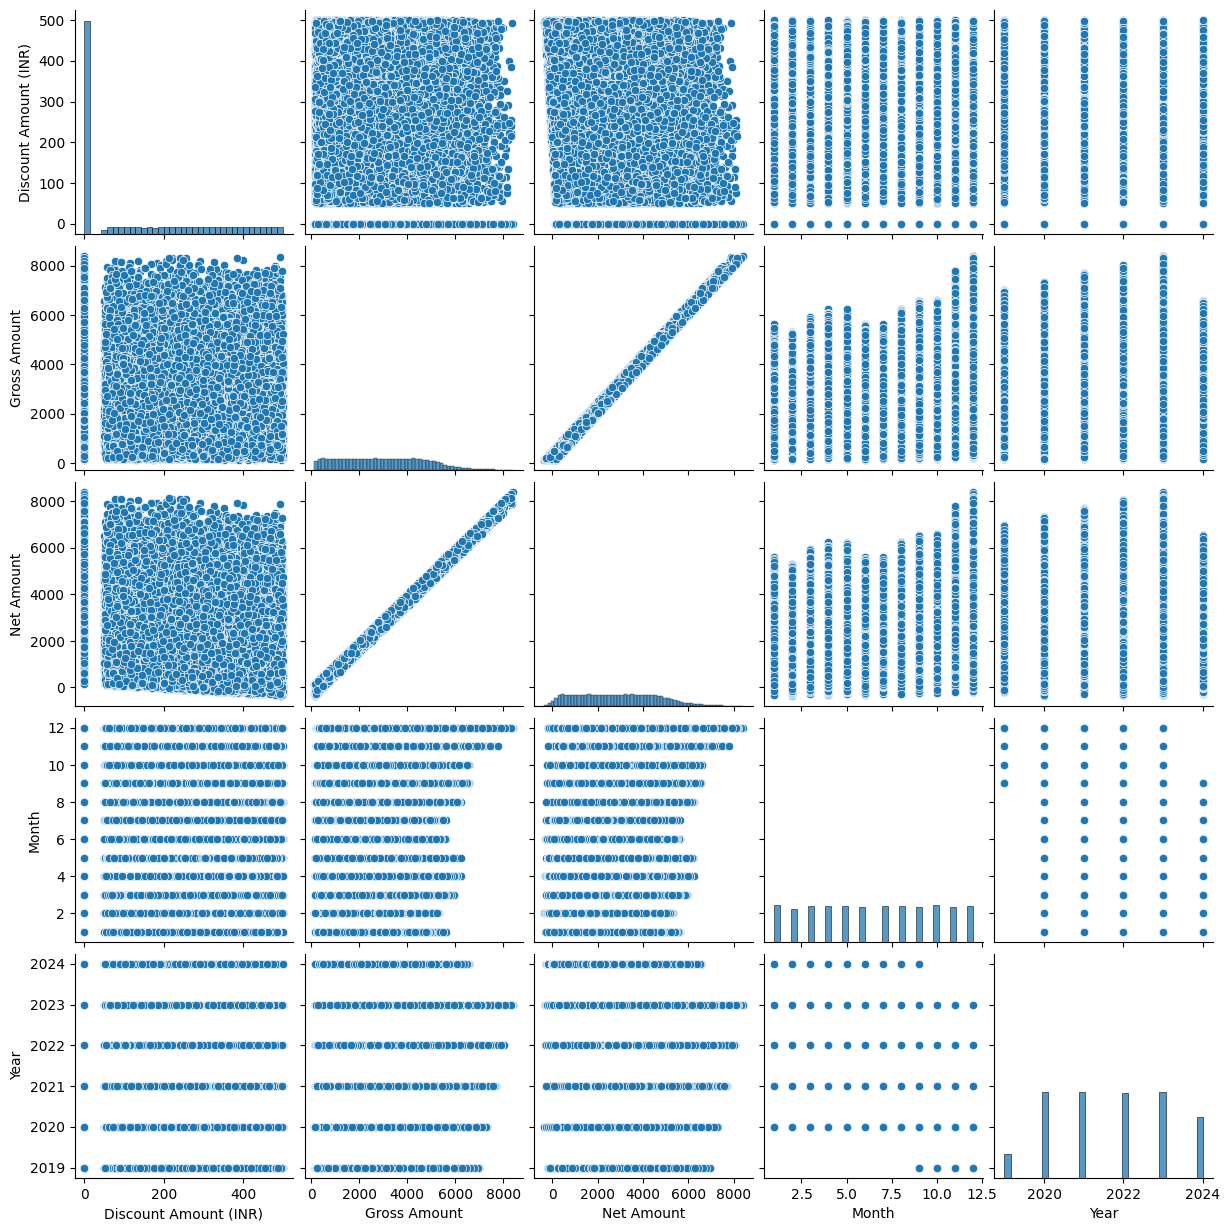

In [69]:
sns.pairplot(da)